# Early Diabetes Detection Using Symptoms

### <u>Problem Statement</u>
Inadequate insulin production or inresponsiveness of body cells to insulin may cause an increase in blood glucose in the body of a person and causing diabetes. Diabetes could cause many other complications, such as loss of vision, kidney infection, and heart problems. Hence, early detection of diabetes can help the patients to keep their sugar levels under control by taking healthy diet with required drugs. 

### <u>Main Objectives</u>
To build an efficient model that can help the patients to detect if they have diabetes. <br>

### <u>Dataset Description</u>
This dataset is originally from <a href="https://archive.ics.uci.edu/ml/datasets/Early+stage+diabetes+risk+prediction+dataset.#">UCI Machine Learning Repository</a>. It contains the sign and symptpom data of newly diabetic or would be diabetic patient.
<br>
<img src="https://images.pexels.com/photos/5469026/pexels-photo-5469026.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" alt="Glucose Meter Surrounded by Sweet Treats on a Blue Surface"/> 

# Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
%matplotlib inline
import seaborn as sns
sns.set_style('darkgrid')
from IPython.display import display, HTML

from scipy.stats import chi2_contingency
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as imbpipeline
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
# from imblearn.over_sampling import ADASYN
# from imblearn.combine import SMOTEENN
# from imblearn.combine import SMOTETomek
# from collections import Counter
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold,cross_val_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import learning_curve, validation_curve

from sklearn.linear_model import LogisticRegression 
from sklearn.neighbors import KNeighborsClassifier  
from sklearn.tree import DecisionTreeClassifier as DT 
from sklearn.ensemble import RandomForestClassifier as RF 
from sklearn import tree
from sklearn.tree import plot_tree
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier 
from sklearn.naive_bayes import GaussianNB as GB  
from sklearn.svm import SVC   

In [2]:
diabetes_df = pd.read_csv("https://raw.githubusercontent.com/jadanpl/Early-Diabetes-Detection-Using-Symptoms/main/diabetes_data.csv")

# Descriptive Statistics

In [3]:
diabetes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 520 non-null    int64
 1   Gender              520 non-null    str  
 2   Polyuria            520 non-null    str  
 3   Polydipsia          520 non-null    str  
 4   sudden weight loss  520 non-null    str  
 5   weakness            520 non-null    str  
 6   Polyphagia          520 non-null    str  
 7   Genital thrush      520 non-null    str  
 8   visual blurring     520 non-null    str  
 9   Itching             520 non-null    str  
 10  Irritability        520 non-null    str  
 11  delayed healing     520 non-null    str  
 12  partial paresis     520 non-null    str  
 13  muscle stiffness    520 non-null    str  
 14  Alopecia            520 non-null    str  
 15  Obesity             520 non-null    str  
 16  class               520 non-null    str  
dtypes: int64

From the result above, only 'Age' column has numerical values as its input, while other columns have categorical inputs.

In [4]:
diabetes_df.columns = diabetes_df.columns.str.lower()

In [5]:
diabetes_df.sample(5)

,age,gender,polyuria,polydipsia,sudden weight loss,weakness,polyphagia,genital thrush,visual blurring,itching,irritability,delayed healing,partial paresis,muscle stiffness,alopecia,obesity,class
85,49,Female,No,No,Yes,Yes,No,No,No,No,No,No,No,No,No,Yes,Positive
75,55,Female,Yes,Yes,Yes,Yes,No,No,Yes,No,No,No,Yes,No,No,Yes,Positive
478,54,Male,No,No,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,No,Negative
223,55,Male,No,No,No,Yes,Yes,No,Yes,Yes,No,Yes,No,Yes,No,Yes,Negative
287,38,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative


# Explanatory Data Analysis & Hypothesis Testing

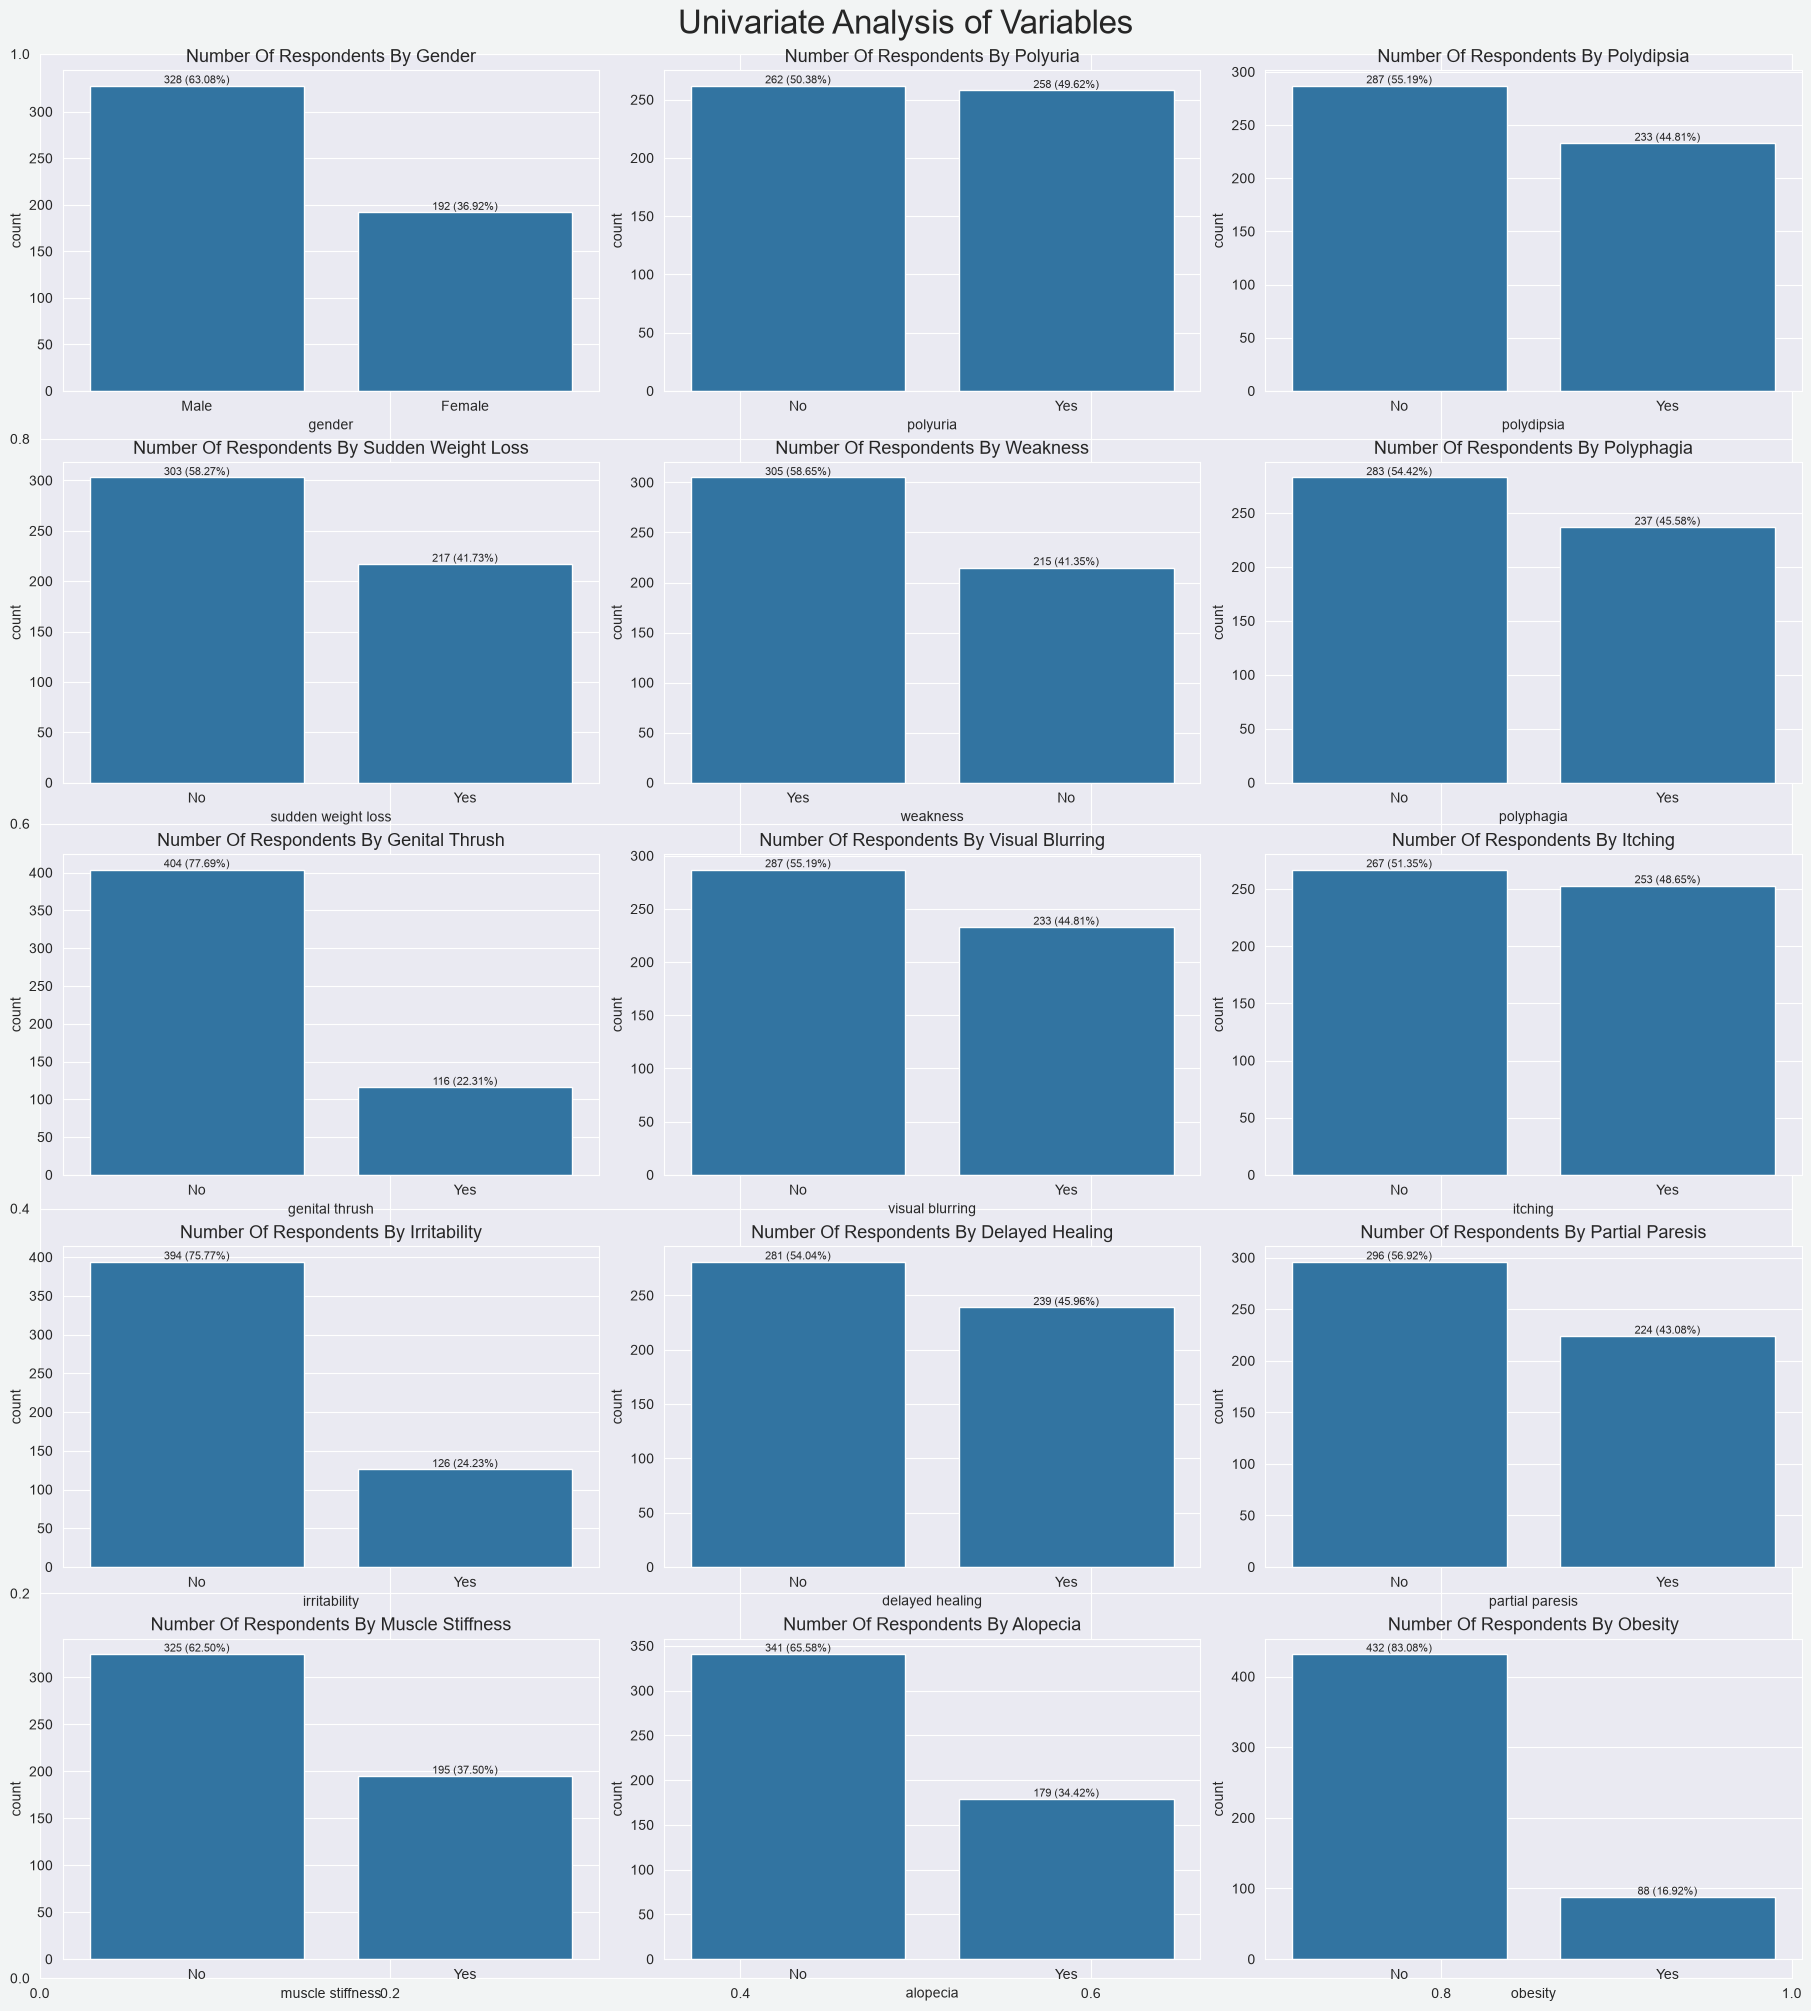

In [6]:
fig, ax = plt.subplots(figsize=(18,20), facecolor='#F2F4F4',constrained_layout=True)

count=1
for i in diabetes_df.columns[1:-1]:
    plt.subplot(5,3,count)
    abs_val = diabetes_df[i].value_counts(ascending=False)
    a = sns.countplot(x=diabetes_df[i], order=abs_val.index)
    rel_val = diabetes_df[i].value_counts(ascending=False, normalize=True).values*100
    lbs_val = [f"{a[0]} ({a[1]:.2f}%)" for a in zip(abs_val,rel_val)]
    a.bar_label(container = a.containers[0], labels = lbs_val, fontsize=8)
    plt.title(('number of respondents by ' + i).title(), fontsize=13)
    count+=1
    
plt.suptitle('Univariate Analysis of Variables',fontsize=24);

In [7]:
chi2_results = []
for col in diabetes_df.columns[1:-1]:
    contingency_table = pd.crosstab(diabetes_df[col], diabetes_df['class'])
    chi2, p_val, dof, _ = chi2_contingency(contingency_table)
    chi2_results.append({'Symptom': col, 'Chi2 Statistic': chi2, 'p-value': p_val})

chi2_df = pd.DataFrame(chi2_results).sort_values(by='Chi2 Statistic', ascending=False).reset_index(drop=True)
display(chi2_df)

,Symptom,Chi2 Statistic,p-value
0,polyuria,227.865839,1.740912e-51
1,polydipsia,216.171633,6.187010e-49
2,gender,103.036859,3.289704e-24
3,sudden weight loss,97.296303,5.969166e-23
4,partial paresis,95.387627,1.565289e-22
5,polyphagia,59.595254,1.165158e-14
6,irritability,45.208348,1.771483e-11
7,alopecia,36.064143,1.909279e-09
8,visual blurring,31.808456,1.701504e-08
9,weakness,29.767918,4.869843e-08


There is a statistically significant relationship between 12 out of 15 categorical symptom variables and diabetes ($p < 0.05$). However, obesity, delayed healing, and itching show no statistically significant association with diabetes status ($p \ge 0.05$) in this dataset. Anyway, in order to preserve data integrity, we will keep these 3 variables because removing features reduces the overall information available to distance-based models (like KNN or SVM) only slightly, so keeping them is generally the safest baseline strategy.

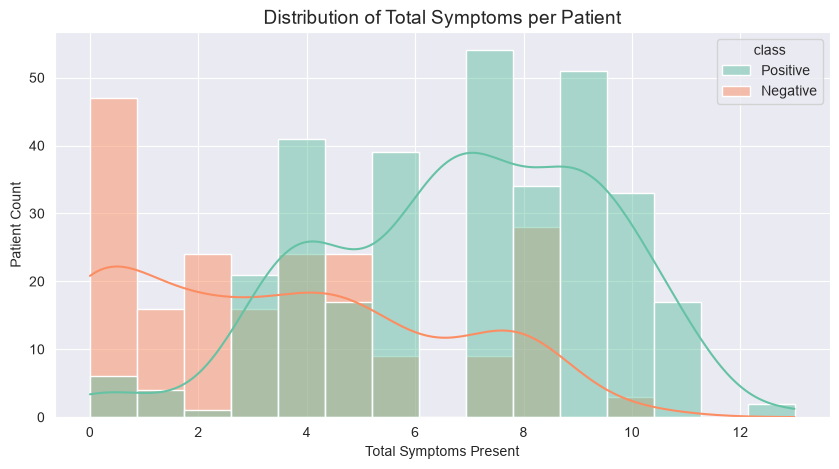

In [8]:
# Count total positive symptoms per patient
symptom_cols = [col for col in diabetes_df.columns if col not in ['age', 'class']]
temp_df = diabetes_df.copy()
temp_df['total_symptoms'] = (temp_df[symptom_cols] == 'Yes').sum(axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(data=temp_df, x='total_symptoms', hue='class', kde=True, bins=15, palette='Set2')
plt.title('Distribution of Total Symptoms per Patient', fontsize=14)
plt.xlabel('Total Symptoms Present')
plt.ylabel('Patient Count')
plt.show()

Cumulative symptom count serves as a strong linear separator for early diabetes detection. While non-diabetic individuals predominantly present with 0–2 symptoms, diabetic patients typically exhibit a high symptom load, peaking between 7 and 9 symptoms. Patients presenting with $\ge 4$ symptoms have a substantially higher probability of testing positive for early-stage diabetes.

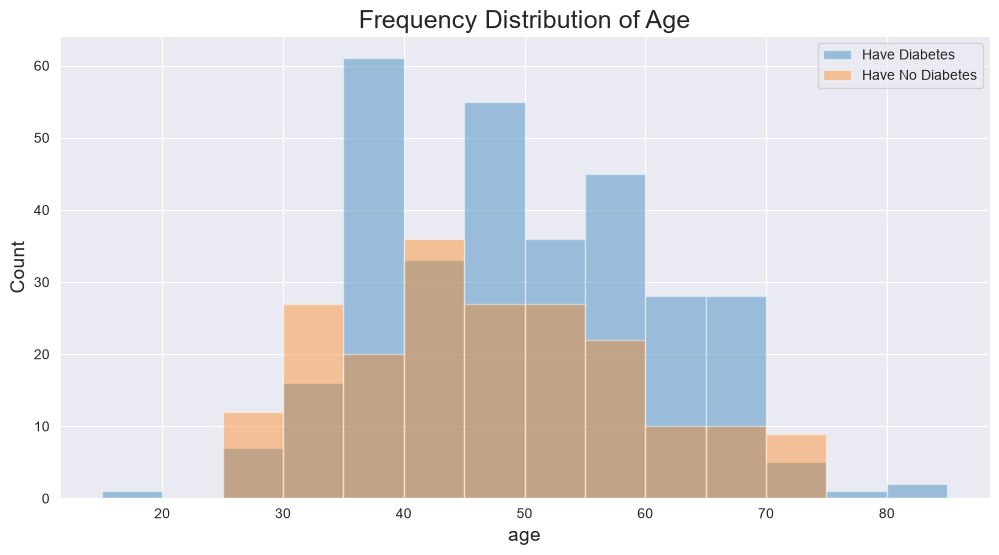

In [9]:
plt.figure(figsize=(12,6))
plt.hist(diabetes_df[diabetes_df['class']=='Positive']['age'], alpha=0.4, bins=np.arange(15, 90, 5),label='Have Diabetes')
plt.hist(diabetes_df[diabetes_df['class']=='Negative']['age'], alpha=0.4, bins=np.arange(15, 90, 5),label='Have No Diabetes')
plt.title('Frequency Distribution of Age',fontsize=18)
plt.xlabel('age',fontsize=14)
plt.ylabel('Count',fontsize=14)
plt.legend();

In [10]:
diabetes_df[(diabetes_df['class']=='Positive') & (diabetes_df['age']<=20) | (diabetes_df['age']>=75)]

,age,gender,polyuria,polydipsia,sudden weight loss,weakness,polyphagia,genital thrush,visual blurring,itching,irritability,delayed healing,partial paresis,muscle stiffness,alopecia,obesity,class
101,85,Male,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,No,Positive
102,90,Female,No,Yes,Yes,No,No,Yes,Yes,Yes,No,No,No,Yes,Yes,No,Positive
113,79,Male,No,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,No,Yes,No,No,No,Positive
133,16,Male,Yes,No,Yes,No,Yes,No,No,No,No,No,No,No,No,No,Positive
185,85,Male,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,No,Positive
186,90,Female,No,Yes,Yes,No,No,Yes,Yes,Yes,No,No,No,Yes,Yes,No,Positive


* Based on the frequency distribution of age, we found out that most of people who have diabetes have age of 35-39. There are also patients who aged of 16 as well as between 75 and 90 in the dataset. 
* Based on the extraction of data above, it is found that all of these minority patients sufferred from sudden weight loss and did not suffer from obesity. Hence, it is suspected that sudden weight loss would be an important variable in the diabetes detection analysis, and vice versa for the obesity variable. However, it requires further analysis to confirm these relationships.

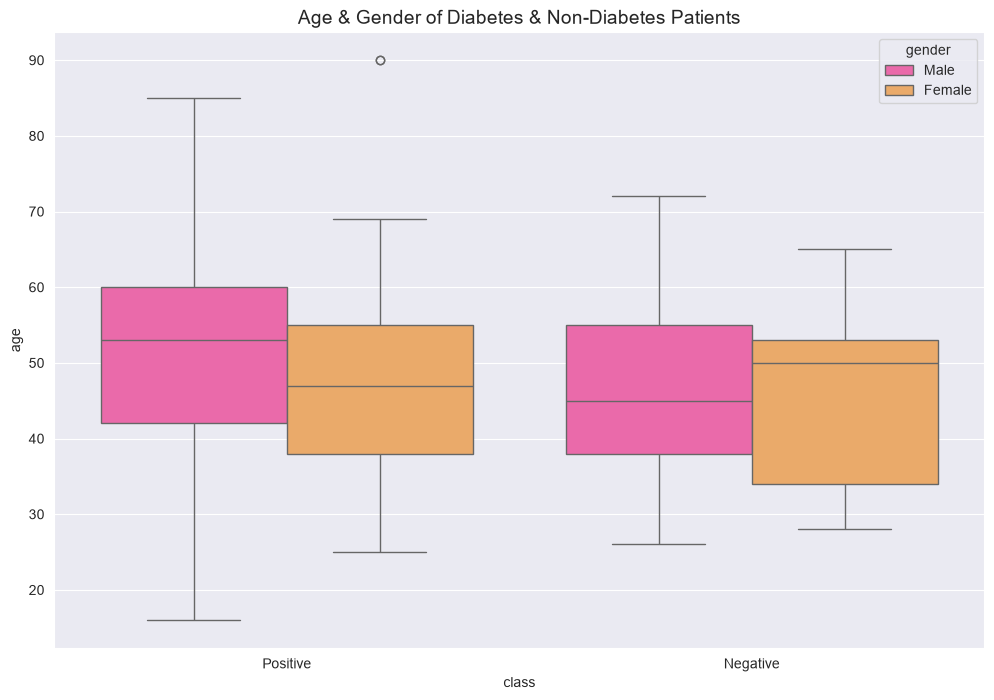

In [11]:
plt.figure(figsize=(12,8))
a = sns.boxplot(y='age', x='class', hue='gender',data=diabetes_df, palette='spring')
plt.title("Age & Gender of Diabetes & Non-Diabetes Patients", fontsize=14);

In [12]:
encoders = {}

for col in diabetes_df.columns[1:]:
    le = LabelEncoder()
    diabetes_df[col] = le.fit_transform(diabetes_df[col])
    encoders[col] = le  # Store the fitted encoder for this column

# --- Now you can view the exact mapping for ANY column ---
for col, le in encoders.items():
    mapping = dict(zip(le.classes_, range(len(le.classes_))))
    print(f"Column '{col}' mapping: {mapping}")

Column 'gender' mapping: {'Female': 0, 'Male': 1}
Column 'polyuria' mapping: {'No': 0, 'Yes': 1}
Column 'polydipsia' mapping: {'No': 0, 'Yes': 1}
Column 'sudden weight loss' mapping: {'No': 0, 'Yes': 1}
Column 'weakness' mapping: {'No': 0, 'Yes': 1}
Column 'polyphagia' mapping: {'No': 0, 'Yes': 1}
Column 'genital thrush' mapping: {'No': 0, 'Yes': 1}
Column 'visual blurring' mapping: {'No': 0, 'Yes': 1}
Column 'itching' mapping: {'No': 0, 'Yes': 1}
Column 'irritability' mapping: {'No': 0, 'Yes': 1}
Column 'delayed healing' mapping: {'No': 0, 'Yes': 1}
Column 'partial paresis' mapping: {'No': 0, 'Yes': 1}
Column 'muscle stiffness' mapping: {'No': 0, 'Yes': 1}
Column 'alopecia' mapping: {'No': 0, 'Yes': 1}
Column 'obesity' mapping: {'No': 0, 'Yes': 1}
Column 'class' mapping: {'Negative': 0, 'Positive': 1}


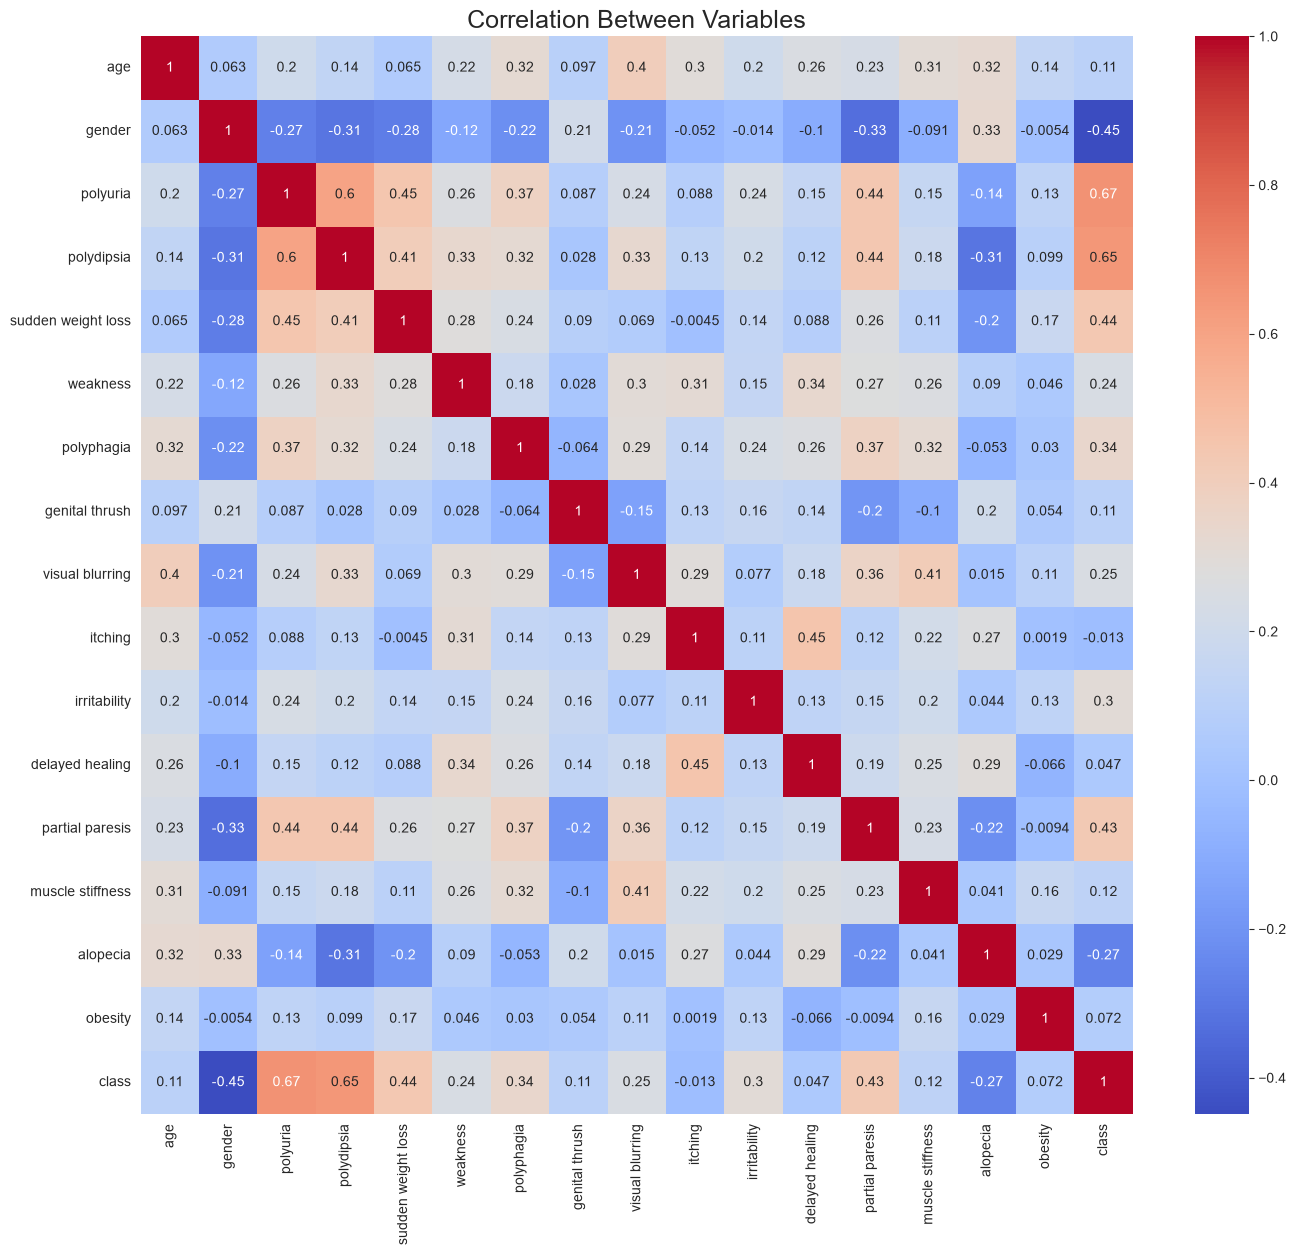

In [13]:
plt.figure(figsize = (16,14))
sns.heatmap(diabetes_df.corr(), annot=True, fmt='.2g',cmap='coolwarm')
plt.title('Correlation Between Variables', fontsize=18);

In [14]:
# Revert 'Gender' back to original strings using its saved encoder
for i in diabetes_df.columns[1:]:
    diabetes_df[i]=encoders[i].inverse_transform(diabetes_df[i])

In [15]:
diabetes_df['class'].value_counts()

class
Positive    320
Negative    200
Name: count, dtype: int64

* There is imbalanced class in the dataset, where the majority class belongs to positive and the minority class belongs to negative label. 
* Hence, `SMOTE` resampling techniques would be used to overcome this issue on the models. 

# Model Building & Evaluation

In [16]:
X = diabetes_df.drop(['class'], axis=1)
Y = diabetes_df['class'].map({'Negative':0,'Positive':1})

In [17]:
num_cols = ['age']
cat_cols = list(X.drop(['age'], axis=1))

transformer = ColumnTransformer([
        ("num", MinMaxScaler(), num_cols),
        ("cat", OneHotEncoder(sparse_output=False, dtype='int', drop="if_binary"), cat_cols)])

Although binary/categorical symptom features (e.g., Yes/No mapped to 1/0) do not require scaling, continuous features like Age must be standardized (Z-score scaling) or normalized (Min-Max scaling) before training distance-based models like K-Nearest Neighbors (KNN) or gradient-based algorithms like Logistic Regression. Without scaling, age values (ranging from 16 to 90) will artificially dominate distance calculations.

In [18]:
# Create training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, stratify=Y)

To get un-biased baseline metric (e.g., Macro Recall or F1-Score), we can run models out-of-the-box with default parameters across 5 folds. Plain cross-validation reveals how sensitive default models are to different data splits (tracked via the standard deviation of cross-validation scores). Therefore, we can eliminate unpromising model families early before spending compute on tuning them.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Define base classifiers
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'KNN': KNeighborsClassifier(metric='euclidean'),
    'Decision Tree': DT(random_state=42),
    'Random Forest': RF(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'Gaussian NB': GB(),
    'SVM': SVC(random_state=42)
}

# Define 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Metrics to track
scoring = ['recall_macro', 'accuracy', 'f1_macro', 'roc_auc']
results = []

# Evaluate baseline models (Without SMOTE)
for name, clf in classifiers.items():
    # Build a leak-free pipeline fitting transformation inside each CV fold
    model_pipeline = Pipeline(steps=[
        ('preprocessor', transformer),
        ('classifier', clf)
    ])
    
    cv_scores = cross_validate(model_pipeline, X_train, Y_train, cv=cv, scoring=scoring)
    
    results.append({
        'Model': name,
        'Recall (Macro) Mean': cv_scores['test_recall_macro'].mean() * 100,
        'Recall (Macro) Std': cv_scores['test_recall_macro'].std() * 100,
        'F1 (Macro) Mean': cv_scores['test_f1_macro'].mean() * 100,
        'ROC-AUC Mean': cv_scores['test_roc_auc'].mean() * 100,
    })

# Format and display sorted baseline results
baseline_df = pd.DataFrame(results).sort_values(by='Recall (Macro) Mean', ascending=False).reset_index(drop=True)
display(baseline_df)

,Model,Recall (Macro) Mean,Recall (Macro) Std,F1 (Macro) Mean,ROC-AUC Mean
0,Random Forest,96.958333,2.449490,96.996028,99.604167
1,SVM,96.000000,1.166667,95.936398,99.097222
2,XGBoost,95.916667,2.022444,95.671279,99.069444
3,Decision Tree,95.041667,2.391391,94.855414,95.041667
4,Logistic Regression,94.416667,0.980717,94.089510,97.375000
5,KNN,93.500000,1.231812,92.792506,98.777778
6,AdaBoost,91.625000,2.490956,91.807912,97.451389
7,Gaussian NB,89.041667,2.110654,89.140723,96.041667


Based on the result above, we will exclude **No. 3 (Decision Tree)**, **No. 6 (AdaBoost)**, and **No. 7 (Gaussian NB)** based on the 5-fold cross-validation baseline metrics:

---
**No. 7: Gaussian NB (Gaussian Naive Bayes)**
* **Weakest Baseline Performance:** Achieves the lowest scores across all evaluation metrics, with a Macro Recall of **89.04%**, F1-Score of **89.14%**, and ROC-AUC of **96.04%**.


* **Violated Independence Assumption:** Naive Bayes assumes strict conditional independence between features given the class label. In symptom-based medical datasets, symptoms (e.g., polyuria and polydipsia) often exhibit high correlation, causing Naive Bayes to underperform compared to tree-based and distance-based classifiers.


**No. 6: AdaBoost**
* **Subpar Performance & High Variance:** Yields the second-lowest Macro Recall (**91.63%**) and F1-Score (**91.81%**) while exhibiting the highest cross-validation standard deviation (**2.49%**).


* **Sensitivity to Noise and Outliers:** Sequential adaptive boosting heavily weights misclassified instances in early iterations, making it prone to fitting noise or boundary anomalies in imbalanced tabular data compared to bagging (Random Forest) or gradient boosting (XGBoost).


**No. 3: Decision Tree**
* **Sub-optimal Generalization vs. Ensemble Counterparts:** While it achieves a reasonable Macro Recall (**95.04%**), its single-tree structure exhibits a noticeably lower ROC-AUC (**95.04%**) compared to ensemble tree models like Random Forest (**99.60%**) and XGBoost (**99.07%**).


* **High Variance & Tendency to Overfit:** Single decision trees are prone to high variance and overfitting on specific feature splits. Since Random Forest and XGBoost directly address the variance issue of individual decision trees through bagging and boosting respectively, retaining the base Decision Tree is redundant.

In [20]:
from imblearn.pipeline import Pipeline as imbpipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Define the remaining 5 models (excluding Decision Tree, AdaBoost, and Gaussian NB)
selected_classifiers = {
    'Random Forest': RF(random_state=42),
    'SVM': SVC(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'KNN': KNeighborsClassifier(metric='euclidean')
}

# Define Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define SMOTE resampler
smote = SMOTE(random_state=42)

# Metrics to track
scoring = ['recall_macro', 'accuracy', 'f1_macro', 'roc_auc']
smote_results = []

# Perform Class Imbalance Correction using imbpipeline
for name, clf in selected_classifiers.items():
    # Construct imbpipeline: Preprocessing -> SMOTE -> Classifier
    smote_pipeline = imbpipeline(steps=[
        ('preprocessor', transformer),
        ('smote', smote),
        ('classifier', clf)
    ])
    
    # Stratified CV ensures SMOTE fits ONLY on training folds inside each loop
    cv_scores = cross_validate(smote_pipeline, X_train, Y_train, cv=cv, scoring=scoring)
    
    smote_results.append({
        'Model': name,
        'Recall (Macro) Mean': cv_scores['test_recall_macro'].mean() * 100,
        'Recall (Macro) Std': cv_scores['test_recall_macro'].std() * 100,
        'F1 (Macro) Mean': cv_scores['test_f1_macro'].mean() * 100,
        'ROC-AUC Mean': cv_scores['test_roc_auc'].mean() * 100,
    })

# Format and display sorted SMOTE results
smote_df = pd.DataFrame(smote_results).sort_values(by='Recall (Macro) Mean', ascending=False).reset_index(drop=True)
display(smote_df)

,Model,Recall (Macro) Mean,Recall (Macro) Std,F1 (Macro) Mean,ROC-AUC Mean
0,Random Forest,96.958333,2.449490,96.996028,99.527778
1,SVM,95.791667,1.081730,95.675387,99.375000
2,XGBoost,95.708333,2.292045,95.411385,98.833333
3,Logistic Regression,93.708333,1.516117,93.054325,97.375000
4,KNN,93.333333,2.493046,92.313207,98.555556


By looking at the baseline and SMOTE cross-validation results, Random Forest maintains the top spot across all metrics, achieving a Macro Recall Mean of 96.96% and ROC-AUC of 99.53%. XGBoost remains a top-tier performer with a Macro Recall Mean of 95.71% and ROC-AUC of 98.83%. 

If we completely removing the two strongest non-linear ensemble models, we will leave with only SVM and Logistic Regression, which rely primarily on linear or smooth decision boundaries. If symptom interactions are non-linear, linear models will underperform on unseen test data.Therefore, we will keep Random Forest, XGBoost, SVM, Logistic Regression, and KNN in the hyperparameter tuning candidate pool (using RandomizedSearchCV).

In [21]:
# 1. Define parameter distributions for RandomizedSearchCV
param_grids = {
    'Random Forest': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [3, 5, 8, None],
        'classifier__min_samples_leaf': [1, 2, 4],
        'classifier__max_features': ['sqrt', 'log2']
    },
    'XGBoost': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [3, 4, 5],
        'classifier__learning_rate': [0.01, 0.05, 0.1],
        'classifier__subsample': [0.8, 1.0]
    },
    'SVM': {
        'classifier__C': [0.1, 1, 10],
        'classifier__kernel': ['rbf', 'linear'],
        'classifier__gamma': ['scale', 'auto']
    },
    'Logistic Regression': {
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__penalty': ['l2']
    },
    'KNN': {
        'classifier__n_neighbors': [3, 5, 7, 9, 11],
        'classifier__weights': ['uniform', 'distance'],
        'classifier__metric': ['euclidean', 'manhattan']
    }
}

In [22]:
# 2. Define base classifiers
classifiers = {
    'Random Forest': RF(random_state=42),
    'SVM': SVC(random_state=42, probability=True),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'KNN': KNeighborsClassifier(),
}

# 3. Setup Stratified K-Fold CV & SMOTE
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
smote = SMOTE(random_state=42)

# Multi-metric evaluation dictionary 
scoring = {
    'recall_macro': 'recall_macro',
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'roc_auc': 'roc_auc',
}

tuned_results = []
best_estimators = {}

# 4. Perform RandomizedSearchCV across all 5 models
for name, clf in classifiers.items():
    # Build complete imbpipeline
    pipeline = imbpipeline(
        steps=[
            ('preprocessor', transformer),
            ('smote', smote),
            ('classifier', clf),
        ]
    )

    # Initialize RandomizedSearchCV
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=20,  # 20 random hyperparameter combinations per model
        scoring=scoring,
        refit='recall_macro',  # Select best model using Macro Recall
        cv=cv,
        random_state=42,
        n_jobs=-1,
    )

    # Fit on un-transformed training data
    random_search.fit(X_train, Y_train)

    # Store best estimator
    best_estimators[name] = random_search.best_estimator_

    # Extract cross-validation scores for the best parameter combination
    best_index = random_search.best_index_
    mean_recall_std = random_search.cv_results_['std_test_recall_macro'][
        best_index
    ]

    tuned_results.append({
        'Model': name,
        'Recall (Macro) Mean': random_search.best_score_ * 100,
        'Recall (Macro) Std': mean_recall_std * 100,
        'F1 (Macro) Mean': random_search.cv_results_['mean_test_f1_macro'][
            best_index
        ]
        * 100,
        'ROC-AUC Mean': random_search.cv_results_['mean_test_roc_auc'][
            best_index
        ]
        * 100,
        'Best Parameters': random_search.best_params_,
    })

# 5. Display comparison table sorted by Recall (Macro) Mean
tuned_df = (
    pd.DataFrame(tuned_results)
    .sort_values(by='Recall (Macro) Mean', ascending=False)
    .reset_index(drop=True)
)

display(tuned_df[['Model', 'Recall (Macro) Mean', 'Recall (Macro) Std', 'F1 (Macro) Mean', 'ROC-AUC Mean']])

,Model,Recall (Macro) Mean,Recall (Macro) Std,F1 (Macro) Mean,ROC-AUC Mean
0,XGBoost,97.083333,2.479079,97.002348,99.027778
1,Random Forest,96.958333,2.449490,96.996028,99.583333
2,KNN,96.750000,1.168154,96.004873,98.708333
3,SVM,95.875000,1.892969,95.917899,99.097222
4,Logistic Regression,93.708333,1.516117,93.054325,97.375000


Based on the results above, XGBoost is the best model but it has the highest sensitivity. 
* However, this model with 97.08% mean recall but a high standard deviation ($\pm 2.48\%$) could yield a true recall as low as ~92% on certain patient demographics.  
* When training sample sizes are small (such as your dataset of 520 records), individual folds are small. Models with high capacity (like unconstrained decision trees or gradient boosting) easily overfit specific quirks in individual folds.
* If a model is unstable across internal 5-fold splits, it will likely be fragile when exposed to new clinical environments, different hospital systems, or shifting patient populations post-deployment. High fold stability signals strong out-of-sample generalization.

Given that our primary goal is clinical safety and reliable patient outcomes, we would choose KNN as final model because it delivers almost identical Macro Recall (96.75%) while offering superior cross-validation stability (Std Dev of 1.17% vs XGBoost's 2.48%). Its low variance makes it highly dependable across varying patient data splits. Low standard deviation across folds confirms that the model has learned generative underlying patterns (e.g., true symptom-disease relationships) rather than memorizing random statistical noise in small samples.

# Final Model Selection

       KNN MODEL - TEST SET PERFORMANCE EVALUATION
Test Recall (Macro): 95.88%
Test F1-Score (Macro): 95.19%
Test ROC-AUC Score:  98.04%

Detailed Classification Report:
              precision    recall  f1-score   support

Negative (0)       0.91      0.98      0.94        50
Positive (1)       0.99      0.94      0.96        80

    accuracy                           0.95       130
   macro avg       0.95      0.96      0.95       130
weighted avg       0.96      0.95      0.95       130



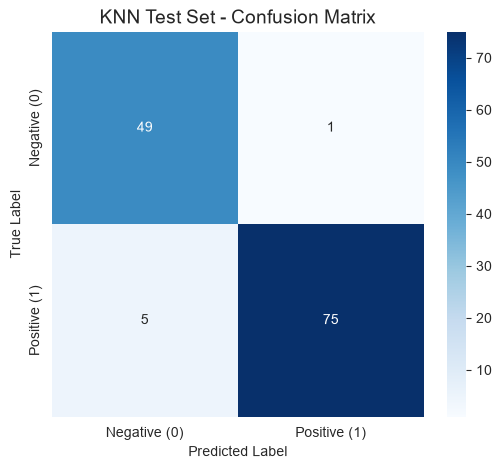

In [23]:
# 1. Retrieve the best-tuned KNN estimator from RandomizedSearchCV
# (Assuming 'best_estimators' stored your random_search.best_estimator_ for KNN)
final_model = best_estimators['KNN']

# 2. Predict class labels and probabilities on unseen test set (X_test)
y_pred_knn = final_model.predict(X_test)
y_pred_proba_knn = final_model.predict_proba(X_test)[:, 1]

# 3. Calculate test performance metrics
test_recall_macro = recall_score(Y_test, y_pred_knn, average='macro') * 100
test_f1_macro = f1_score(Y_test, y_pred_knn, average='macro') * 100
test_roc_auc = roc_auc_score(Y_test, y_pred_proba_knn) * 100

# 4. Display test evaluation summary
print("=" * 50)
print("       KNN MODEL - TEST SET PERFORMANCE EVALUATION")
print("=" * 50)
print(f"Test Recall (Macro): {test_recall_macro:.2f}%")
print(f"Test F1-Score (Macro): {test_f1_macro:.2f}%")
print(f"Test ROC-AUC Score:  {test_roc_auc:.2f}%")
print("\nDetailed Classification Report:")
print(
    classification_report(
        Y_test, y_pred_knn, target_names=['Negative (0)', 'Positive (1)']
    )
)

# 5. Confusion Matrix Visualization
cm = confusion_matrix(Y_test, y_pred_knn)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative (0)', 'Positive (1)'],
    yticklabels=['Negative (0)', 'Positive (1)'],
)
plt.title('KNN Test Set - Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [24]:
final_model

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](16,)","['age','gender','polyuria',...,'muscle stiffness','alopecia','obesity']"
n_features_in_,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


# Making Prediction With New Input

In [25]:
def predict(model, inputs):
    input_df = pd.DataFrame([inputs])
    pred = model.predict(input_df)[0]
    if pred == 0:
        print('It is predicted that this patient does not have diabetes.')
    else: 
        print('It is predicted that this patient would have diabetes.')

In [26]:
male_input = {'age':25, 
               'gender':'Male', 
               'polyuria':'No', 
               'polydipsia':'No', 
               'sudden weight loss':'No',   
               'weakness':'No', 
               'polyphagia':'No', 
               'genital thrush':'No', 
               'visual blurring':'Yes',     
               'itching':'No', 
               'irritability':'No', 
               'delayed healing':'No', 
               'partial paresis':'No',
               'muscle stiffness':'Yes', 
               'alopecia':'No',
              'obesity':'No'}

In [27]:
predict(final_model, male_input)

It is predicted that this patient does not have diabetes.


In [28]:
female_input = {'age':25, 
               'gender':'Female', 
               'polyuria':'No', 
               'polydipsia':'No', 
               'sudden weight loss':'No',   
               'weakness':'No', 
               'polyphagia':'No', 
               'genital thrush':'No', 
               'visual blurring':'Yes',     
               'itching':'No', 
               'irritability':'No', 
               'delayed healing':'No', 
               'partial paresis':'No',
               'muscle stiffness':'Yes', 
               'alopecia':'No', 
               'obesity':'Yes'}

In [29]:
predict(final_model, female_input)

It is predicted that this patient would have diabetes.


# Recommendation

* We could implement ensemble learning, such as by using voting classifier or stacking classifier.
* Other than `SMOTE`, resampling techniques such as `ADASYN`, `SMOTEENN`, or `SMOTETomek` could be used. 
* If it is possible, we could increase the size of dataset by collecting more data. 